# Session 12 · Deep Learning Models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-12-deep-learning-models.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: one neuron and a tiny network in NumPy (forward + backprop)

In [1]:
"""XOR with a 2-4-1 network written in NumPy: forward pass, backpropagation and gradient descent."""
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)          # XOR: not linearly separable
rng = np.random.default_rng(1)
W1, b1 = rng.normal(0, 1, (2, 4)), np.zeros((1, 4))
W2, b2 = rng.normal(0, 1, (4, 1)), np.zeros((1, 1))
sigmoid = lambda z: 1 / (1 + np.exp(-z))

for epoch in range(5001):
    # forward pass
    h = np.tanh(X @ W1 + b1)                 # hidden layer (4 neurons)
    p = sigmoid(h @ W2 + b2)                 # output probability
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    # backward pass (chain rule)
    dz2 = (p - y) / len(X)                   # dLoss/dz for sigmoid + cross-entropy
    dW2, db2 = h.T @ dz2, dz2.sum(0, keepdims=True)
    dh = dz2 @ W2.T * (1 - h ** 2)           # back through tanh
    dW1, db1 = X.T @ dh, dh.sum(0, keepdims=True)
    # gradient descent step
    for P, G in [(W1, dW1), (b1, db1), (W2, dW2), (b2, db2)]:
        P -= 1.0 * G
    if epoch in (0, 100, 1000, 5000):
        print(f"epoch {epoch:>4}: loss = {loss:.4f}  predictions = {p.ravel().round(3)}")
print("rounded predictions:", (p.ravel() > .5).astype(int), " true:", y.ravel().astype(int))

epoch    0: loss = 0.6712  predictions = [0.5   0.659 0.464 0.554]
epoch  100: loss = 0.0379  predictions = [0.011 0.962 0.958 0.057]
epoch 1000: loss = 0.0024  predictions = [0.    0.997 0.997 0.004]
epoch 5000: loss = 0.0005  predictions = [0.    0.999 0.999 0.001]
rounded predictions: [0 1 1 0]  true: [0 1 1 0]


### Example 2 · Intermediate: an ANN in PyTorch with validation and early stopping

In [2]:
"""A PyTorch multilayer perceptron for breast-cancer diagnosis: DataLoader, training loop, early stopping."""
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
torch.manual_seed(0); torch.set_num_threads(2)

X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=0, stratify=y)
X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=.2, random_state=0, stratify=y_tr)
sc = StandardScaler().fit(X_tr)
t = lambda a: torch.tensor(a, dtype=torch.float32)
X_tr, X_va, X_te = t(sc.transform(X_tr)), t(sc.transform(X_va)), t(sc.transform(X_te))
y_tr, y_va, y_te = t(y_tr).unsqueeze(1), t(y_va).unsqueeze(1), t(y_te).unsqueeze(1)
loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)

model = nn.Sequential(nn.Linear(30, 32), nn.ReLU(), nn.Dropout(0.2),
                      nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))      # outputs a logit
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
loss_fn = nn.BCEWithLogitsLoss()                                         # sigmoid + binary cross-entropy
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

best, best_state, patience, wait = np.inf, None, 15, 0
for epoch in range(300):
    model.train()
    for xb, yb in loader:
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        val = loss_fn(model(X_va), y_va).item()
    if val < best - 1e-4:
        best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
    else:
        wait += 1
    if epoch % 20 == 0:
        print(f"epoch {epoch:>3}: train loss {loss.item():.4f}  val loss {val:.4f}")
    if wait >= patience:
        print(f"early stopping at epoch {epoch} (best val loss {best:.4f})"); break

model.load_state_dict(best_state); model.eval()
with torch.no_grad():
    acc = ((model(X_te) > 0).float() == y_te).float().mean().item()
print(f"test accuracy: {acc:.3f}")

Sequential(
  (0): Linear(in_features=30, out_features=32, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=32, out_features=16, bias=True)
  (4): ReLU()
  (5): Linear(in_features=16, out_features=1, bias=True)
)
trainable parameters: 1537


epoch   0: train loss 0.6967  val loss 0.6831


epoch  20: train loss 0.0407  val loss 0.0350


epoch  40: train loss 0.0135  val loss 0.0214


epoch  60: train loss 0.0040  val loss 0.0164


epoch  80: train loss 0.0112  val loss 0.0143


epoch 100: train loss 0.0029  val loss 0.0136
early stopping at epoch 106 (best val loss 0.0119)
test accuracy: 0.956


### Example 3 · Intermediate: a CNN for handwritten digits, with feature maps

parameters: 18346


epoch  5: last batch loss 0.339  test accuracy 0.898


epoch 10: last batch loss 0.210  test accuracy 0.949


epoch 15: last batch loss 0.260  test accuracy 0.958


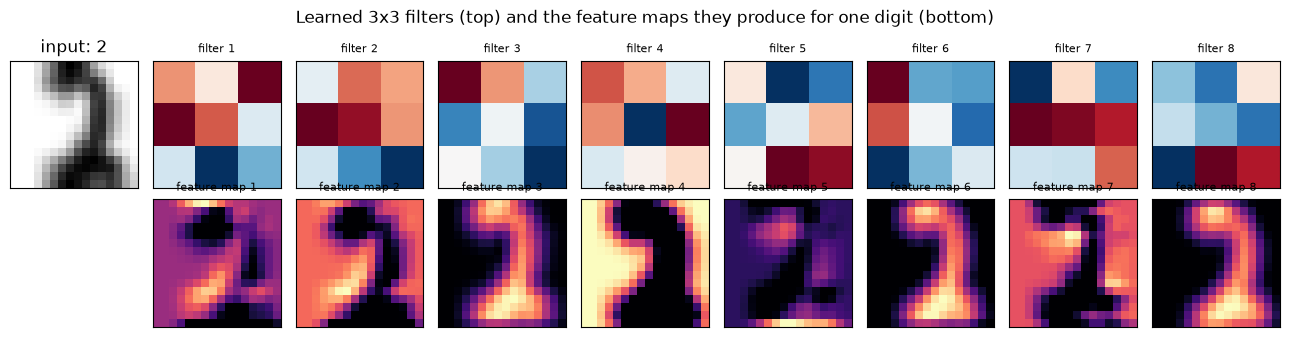

In [3]:
"""A small CNN on 8x8 digit images (upscaled to 16x16): training, test accuracy, filters and feature maps."""
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
torch.manual_seed(0); torch.set_num_threads(2)

digits = load_digits()
X = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)      # (n, 1, 8, 8)
X = F.interpolate(X, size=16, mode="bilinear", align_corners=False)            # 16x16 for two pooling layers
y = torch.tensor(digits.target)
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=.25, random_state=0, stratify=digits.target)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)      # 16x16 -> 8 maps of 16x16
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)     # after pool 8x8 -> 16 maps of 8x8
        self.fc1 = nn.Linear(16 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, 10)
        self.drop = nn.Dropout(0.3)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)      # -> 8 x 8 x 8
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)      # -> 16 x 4 x 4
        x = self.drop(F.relu(self.fc1(x.flatten(1))))
        return self.fc2(x)

model = SmallCNN()
print("parameters:", sum(p.numel() for p in model.parameters()))
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
for epoch in range(15):
    model.train()
    perm = torch.tensor(np.random.default_rng(epoch).permutation(idx_tr))
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]
        opt.zero_grad(); loss = F.cross_entropy(model(X[b]), y[b]); loss.backward(); opt.step()
    if epoch % 5 == 4:
        model.eval()
        with torch.no_grad():
            acc = (model(X[idx_te]).argmax(1) == y[idx_te]).float().mean().item()
        print(f"epoch {epoch + 1:>2}: last batch loss {loss.item():.3f}  test accuracy {acc:.3f}")

model.eval()
with torch.no_grad():
    maps = F.relu(model.conv1(X[idx_te[:1]]))[0]
fig, ax = plt.subplots(2, 9, figsize=(13, 3.4))
ax[0, 0].imshow(X[idx_te[0], 0], cmap="gray_r"); ax[0, 0].set_title(f"input: {y[idx_te[0]].item()}")
ax[1, 0].axis("off")
for k in range(8):
    ax[0, k + 1].imshow(model.conv1.weight[k, 0].detach(), cmap="RdBu"); ax[0, k + 1].set_title(f"filter {k + 1}", fontsize=8)
    ax[1, k + 1].imshow(maps[k], cmap="magma"); ax[1, k + 1].set_title(f"feature map {k + 1}", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
fig.suptitle("Learned 3x3 filters (top) and the feature maps they produce for one digit (bottom)")
fig.tight_layout(); fig.savefig("session-12_cnn_feature_maps.png", dpi=100); plt.show()

### Example 4 · Advanced: vanishing gradients (RNN vs LSTM) and an LSTM forecaster

In [4]:
"""Why LSTMs matter: how much does the FIRST input still influence the last hidden state? Then an LSTM forecaster."""
import numpy as np
import torch
from torch import nn
torch.set_num_threads(2)

def gradient_to_first_input(cell, length, trials=20):
    """Average |d h_last / d x_0| over random initialisations: the signal that reaches step 0 in backprop."""
    vals = []
    for k in range(trials):
        torch.manual_seed(k)
        rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[cell](1, 32, batch_first=True)
        if cell == "LSTM":                       # common practice: forget-gate bias = 1 (remember by default)
            with torch.no_grad():
                for name, p in rnn.named_parameters():
                    if "bias_ih" in name:
                        p[32:64] = 1.0
        x = torch.randn(1, length, 1, requires_grad=True)
        h, _ = rnn(x)
        h[0, -1].sum().backward()
        vals.append(x.grad[0, 0, 0].abs().item())
    return np.mean(vals)

print("sequence length   gradient reaching step 0:  plain RNN      LSTM")
for length in [5, 20, 50, 100]:
    print(f"{length:>15}   {'':>24}{gradient_to_first_input('RNN', length):9.1e}{gradient_to_first_input('LSTM', length):10.1e}")

# Many-to-one forecasting: predict the next value from the previous 24
t = np.arange(1500)
series = np.sin(2 * np.pi * t / 50) + 0.5 * np.sin(2 * np.pi * t / 13) + np.random.default_rng(0).normal(0, .1, 1500)
W = 24
Xs = torch.tensor(np.stack([series[i:i + W] for i in range(len(series) - W)]), dtype=torch.float32).unsqueeze(2)
ys = torch.tensor(series[W:], dtype=torch.float32)
split = 1200
lstm = nn.LSTM(1, 32, batch_first=True); head = nn.Linear(32, 1)
opt = torch.optim.Adam(list(lstm.parameters()) + list(head.parameters()), lr=5e-3)
for epoch in range(20):
    for i in range(0, split, 64):
        h, _ = lstm(Xs[i:i + 64]); pred = head(h[:, -1]).squeeze(1)
        opt.zero_grad(); loss = nn.functional.mse_loss(pred, ys[i:i + 64]); loss.backward(); opt.step()
with torch.no_grad():
    h, _ = lstm(Xs[split:]); pred = head(h[:, -1]).squeeze(1)
mae = (pred - ys[split:]).abs().mean().item()
naive = (Xs[split:, -1, 0] - ys[split:]).abs().mean().item()
print(f"\nLSTM next-step forecast MAE on unseen data: {mae:.3f}  (naive 'same as last value': {naive:.3f})")

sequence length   gradient reaching step 0:  plain RNN      LSTM
              5                             3.0e-02   4.0e-02


             20                             1.3e-05   2.1e-03
             50                             8.1e-12   2.6e-05


            100                             3.0e-21   3.8e-08



LSTM next-step forecast MAE on unseen data: 0.099  (naive 'same as last value': 0.198)


### 🏙️ Real-life data problem: classifying customer reviews (many-to-one text RNN)

In [5]:
"""Real-life problem: sentiment of food-delivery reviews with an Embedding + GRU network vs a TF-IDF baseline."""
import numpy as np
import torch
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
torch.manual_seed(0); torch.set_num_threads(2)
rng = np.random.default_rng(0)

pos_bits = ["food was delicious", "rider was very polite", "arrived hot and fresh", "great taste", "fast delivery",
            "will order again", "portion was generous", "biryani was amazing", "packaging was neat", "excellent service"]
neg_bits = ["food was cold", "rider was rude", "arrived very late", "tasted stale", "order was missing items",
            "never ordering again", "portion was tiny", "biryani was too oily", "packaging was leaking", "terrible service"]
neutral = ["ordered on friday", "for my family", "at lunch time", "from the new branch", "", "using the app"]
def make_review(label):
    good, bad = (pos_bits, neg_bits) if label else (neg_bits, pos_bits)
    parts = list(rng.choice(good, 2, replace=False)) + [rng.choice(neutral)]
    if rng.random() < .40:                                  # mixed reviews: one opposite remark
        parts.append("but " + rng.choice(bad))
        parts.append(rng.choice(good))
    if rng.random() < .15:                                  # negation flips a positive phrase
        parts.append("not " + rng.choice(bad).split(" was ")[-1] if label else "not great at all")
    rng.shuffle(parts)
    return " ".join(p for p in parts if p)

labels = rng.integers(0, 2, 4000)
texts = [make_review(l) for l in labels]
noisy = rng.random(4000) < .06                              # 6% of reviews carry a wrong star rating (real data is noisy)
labels = np.where(noisy, 1 - labels, labels)
tr, te = np.arange(3200), np.arange(3200, 4000)
print("example reviews:"); [print(f"  [{labels[i]}] {texts[i]}") for i in range(3)]

# Baseline: TF-IDF + logistic regression
vec = TfidfVectorizer(ngram_range=(1, 2)).fit([texts[i] for i in tr])
base = LogisticRegression(max_iter=1000).fit(vec.transform([texts[i] for i in tr]), labels[tr])
print(f"\nTF-IDF + logistic regression test accuracy: {base.score(vec.transform([texts[i] for i in te]), labels[te]):.3f}")

# Vocabulary and padded integer sequences
vocab = {"<pad>": 0, "<unk>": 1}
for i in tr:
    for w in texts[i].split():
        vocab.setdefault(w, len(vocab))
MAXLEN = 30
def encode(s):
    ids = [vocab.get(w, 1) for w in s.split()][:MAXLEN]
    return ids + [0] * (MAXLEN - len(ids))
X = torch.tensor([encode(s) for s in texts]); Y = torch.tensor(labels, dtype=torch.float32)
print("vocabulary size:", len(vocab))

class ReviewGRU(nn.Module):
    def __init__(self, vocab_size, emb=32, hidden=32):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.gru = nn.GRU(emb, hidden, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hidden, 1)
    def forward(self, x):
        h, _ = self.gru(self.emb(x))
        mask = (x != 0).unsqueeze(2).float()
        pooled = (h * mask).sum(1) / mask.sum(1).clamp(min=1)     # average over real (non-pad) words
        return self.out(pooled).squeeze(1)

model = ReviewGRU(len(vocab)); opt = torch.optim.Adam(model.parameters(), lr=3e-3)
for epoch in range(8):
    model.train(); perm = torch.tensor(rng.permutation(tr))
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]
        opt.zero_grad(); loss = nn.functional.binary_cross_entropy_with_logits(model(X[b]), Y[b]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = ((model(X[te]) > 0).float() == Y[te]).float().mean().item()
    if epoch % 2 == 1:
        print(f"epoch {epoch + 1}: GRU test accuracy {acc:.3f}")

new = ["rider was very polite and food was delicious", "arrived very late and food was cold",
       "great taste but packaging was leaking", "biryani was amazing will order again"]
with torch.no_grad():
    probs = torch.sigmoid(model(torch.tensor([encode(s) for s in new]))).numpy()
for s, p in zip(new, probs):
    print(f"P(positive) = {p:.2f}  {s}")

example reviews:
  [1] excellent service ordered on friday great taste
  [1] arrived hot and fresh but tasted stale food was delicious will order again
  [1] great taste biryani was amazing ordered on friday



TF-IDF + logistic regression test accuracy: 0.931


vocabulary size: 59


epoch 2: GRU test accuracy 0.931


epoch 4: GRU test accuracy 0.931


epoch 6: GRU test accuracy 0.931


epoch 8: GRU test accuracy 0.931
P(positive) = 0.99  rider was very polite and food was delicious
P(positive) = 0.30  arrived very late and food was cold
P(positive) = 0.90  great taste but packaging was leaking
P(positive) = 0.96  biryani was amazing will order again


### 🧩 Mini project: activity recognition from phone sensors with a 1-D CNN

In [6]:
"""Mini project: classify walking, running, sitting and climbing stairs from simulated accelerometer windows (1-D CNN)."""
import numpy as np
import torch
from torch import nn
torch.manual_seed(0); torch.set_num_threads(2)
rng = np.random.default_rng(0)

activities = ["sitting", "walking", "running", "stairs"]
def window(label, n=64):
    t = np.arange(n) / 32.0                                    # 2 seconds at 32 Hz
    if label == 0:
        sig = np.c_[0.02 * rng.normal(size=n), 0.02 * rng.normal(size=n), 1 + 0.02 * rng.normal(size=n)]
    else:
        f, amp = {1: (1.8, .35), 2: (2.6, .8), 3: (1.6, .4)}[label]
        ph = rng.uniform(0, 2 * np.pi)
        z = 1 + amp * np.sin(2 * np.pi * f * t + ph)
        x = .5 * amp * np.sin(2 * np.pi * f / 2 * t + ph)
        y = (.3 if label == 3 else .1) * np.sin(2 * np.pi * f * t + ph + 1)    # stairs: more sideways sway
        sig = np.c_[x, y, z] + 0.35 * rng.normal(size=(n, 3))          # noisy phone sensor
    return sig.T                                               # (3 channels, 64 time steps)

y = rng.integers(0, 4, 2400)
X = torch.tensor(np.stack([window(l) for l in y]), dtype=torch.float32)
Y = torch.tensor(y)
tr, te = np.arange(2000), np.arange(2000, 2400)

model = nn.Sequential(nn.Conv1d(3, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
                      nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
                      nn.Flatten(), nn.Linear(32, 4))
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
for epoch in range(10):
    perm = torch.tensor(rng.permutation(tr))
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]
        opt.zero_grad(); loss = nn.functional.cross_entropy(model(X[b]), Y[b]); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    pred = model(X[te]).argmax(1)
print(f"test accuracy: {(pred == Y[te]).float().mean().item():.3f}")
conf = np.zeros((4, 4), int)
for t_, p_ in zip(Y[te].numpy(), pred.numpy()):
    conf[t_, p_] += 1
print("confusion matrix (rows = true, columns = predicted):")
print("          " + " ".join(f"{a[:7]:>8}" for a in activities))
for a, row in zip(activities, conf):
    print(f"{a:<10}" + " ".join(f"{v:>8}" for v in row))

test accuracy: 0.962
confusion matrix (rows = true, columns = predicted):
           sitting  walking  running   stairs
sitting        100        0        0        0
walking          0       88        1        4
running          0        0       92        0
stairs           0       10        0      105
